# Heart Disease Classification

An end-to-end binary classification project using a small clinical dataset.

**Objective:** compare several machine-learning models and estimate whether a participant belongs to the heart-disease class.

> Educational project only. The model is not a medical diagnostic tool.


In [120]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from catboost import CatBoostClassifier
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, brier_score_loss,
    classification_report, confusion_matrix, f1_score, log_loss,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, RepeatedStratifiedKFold,
    StratifiedKFold, cross_val_predict, cross_validate, train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


## 1. Load the data

The dataset contains 303 observations. The target indicates the presence or absence of heart disease.


In [121]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "heart_disease_classification_dataset.csv"

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()


Shape: (303, 15)


,Unnamed: 0,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,0,63,male,3,145.0,233.0,1,0,150.0,0,2.3,0,0,1,yes
1,1,37,male,2,130.0,250.0,0,1,187.0,0,3.5,0,0,2,yes
2,2,41,female,1,130.0,204.0,0,0,172.0,0,1.4,2,0,2,yes
3,3,56,male,1,120.0,236.0,0,1,178.0,0,0.8,2,0,2,yes
4,4,57,female,0,NaN,354.0,0,1,163.0,1,0.6,2,0,2,yes


In [122]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  303 non-null    int64  
 1   age         303 non-null    int64  
 2   sex         303 non-null    str    
 3   cp          303 non-null    int64  
 4   trestbps    299 non-null    float64
 5   chol        302 non-null    float64
 6   fbs         303 non-null    int64  
 7   restecg     303 non-null    int64  
 8   thalach     298 non-null    float64
 9   exang       303 non-null    int64  
 10  oldpeak     303 non-null    float64
 11  slope       303 non-null    int64  
 12  ca          303 non-null    int64  
 13  thal        303 non-null    int64  
 14  target      303 non-null    str    
dtypes: float64(4), int64(9), str(2)
memory usage: 35.6 KB


In [123]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,303.0,NaN,NaN,NaN,151.0,87.612784,0.0,75.5,151.0,226.5,302.0
age,303.0,NaN,NaN,NaN,54.366337,9.082101,29.0,47.5,55.0,61.0,77.0
sex,303,2,male,207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cp,303.0,NaN,NaN,NaN,0.966997,1.032052,0.0,0.0,1.0,2.0,3.0
trestbps,299.0,NaN,NaN,NaN,131.712375,17.629032,94.0,120.0,130.0,140.0,200.0
chol,302.0,NaN,NaN,NaN,246.317881,51.908285,126.0,211.0,240.5,274.75,564.0
fbs,303.0,NaN,NaN,NaN,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,NaN,NaN,NaN,0.528053,0.52586,0.0,0.0,1.0,1.0,2.0
thalach,298.0,NaN,NaN,NaN,149.865772,22.563687,71.0,134.5,152.5,166.0,202.0
exang,303.0,NaN,NaN,NaN,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0


## 2. Clean the data

- `Unnamed: 0` is an exported index and is removed.
- `sex` and `target` are converted to binary values.
- Missing numerical values will be imputed inside the pipelines.


In [124]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
df["sex"] = df["sex"].map({"female": 0, "male": 1})
df["target"] = df["target"].map({"no": 0, "yes": 1})

assert df["sex"].notna().all()
assert df["target"].notna().all()
df.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145.0,233.0,1,0,150.0,0,2.3,0,0,1,1
1,37,1,2,130.0,250.0,0,1,187.0,0,3.5,0,0,2,1
2,41,0,1,130.0,204.0,0,0,172.0,0,1.4,2,0,2,1
3,56,1,1,120.0,236.0,0,1,178.0,0,0.8,2,0,2,1
4,57,0,0,NaN,354.0,0,1,163.0,1,0.6,2,0,2,1


In [125]:
quality_summary = pd.DataFrame({
    "dtype": df.dtypes,
    "missing": df.isna().sum(),
    "unique_values": df.nunique(),
})
print("Duplicate rows:", df.duplicated().sum())
quality_summary


Duplicate rows: 1


,dtype,missing,unique_values
age,int64,0,41
sex,int64,0,2
cp,int64,0,4
trestbps,float64,4,49
chol,float64,1,152
fbs,int64,0,2
restecg,int64,0,3
thalach,float64,5,89
exang,int64,0,2
oldpeak,float64,0,40


## 3. Exploratory data analysis

The EDA describes this dataset only. Associations in these plots are not proof of causality.


,count,proportion
target,,
0,138,0.455446
1,165,0.544554


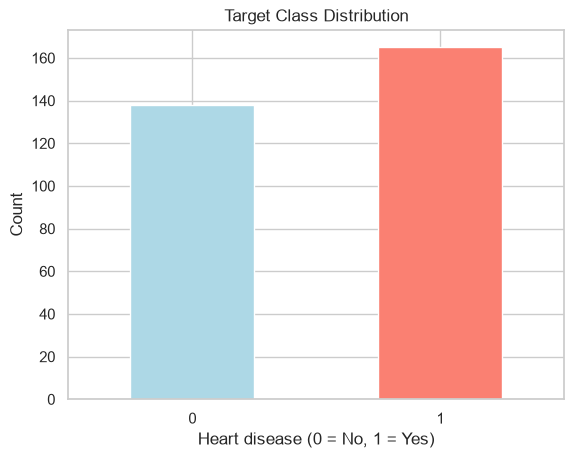

In [126]:
target_counts = df["target"].value_counts().sort_index()
target_proportions = df["target"].value_counts(normalize=True).sort_index()
display(pd.DataFrame({"count": target_counts, "proportion": target_proportions}))

target_counts.plot(kind="bar", color=["lightblue", "salmon"])
plt.title("Target Class Distribution")
plt.xlabel("Heart disease (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()


The classes are reasonably balanced. A majority-class baseline is useful, but accuracy alone is not sufficient.


target,0,1
sex,,
0,24,72
1,114,93


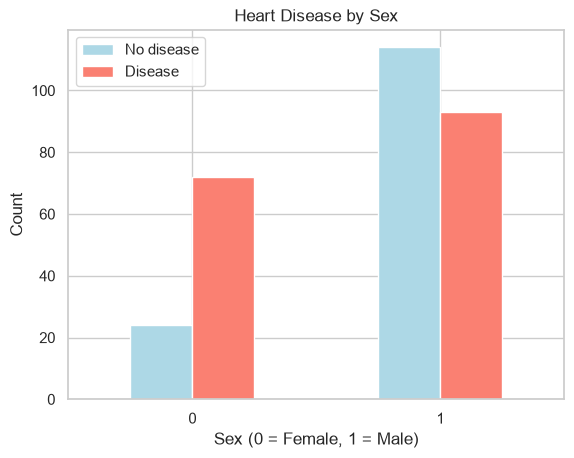

In [127]:
sex_target = pd.crosstab(df["sex"], df["target"])
display(sex_target)
sex_target.plot(kind="bar", color=["lightblue", "salmon"])
plt.title("Heart Disease by Sex")
plt.xlabel("Sex (0 = Female, 1 = Male)")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.legend(["No disease", "Disease"])
plt.show()


Women have a larger positive proportion in this sample. This may reflect the dataset composition and should not be generalized.


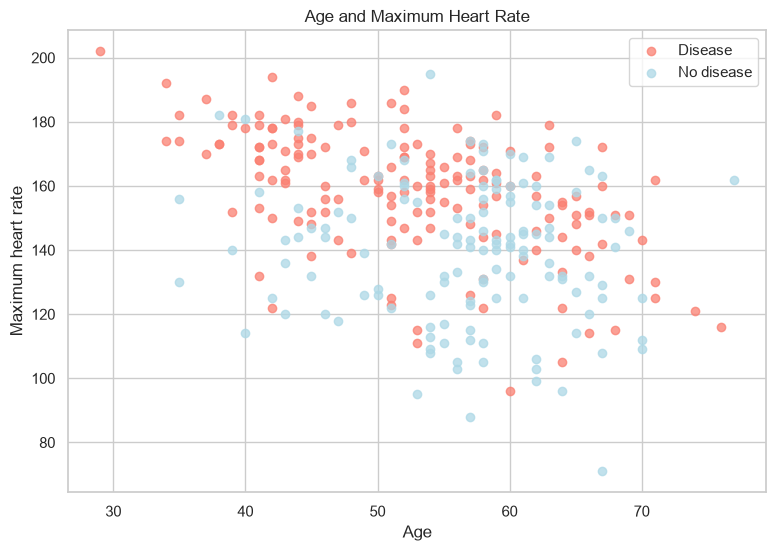

In [128]:
plt.figure(figsize=(9, 6))
for value, color, label in [(1, "salmon", "Disease"), (0, "lightblue", "No disease")]:
    subset = df[df["target"] == value]
    plt.scatter(subset["age"], subset["thalach"], c=color, label=label, alpha=0.75)
plt.title("Age and Maximum Heart Rate")
plt.xlabel("Age")
plt.ylabel("Maximum heart rate")
plt.legend()
plt.show()


Maximum heart rate tends to decrease with age. The two classes overlap, so these variables cannot separate them alone.


target,0,1
cp,,
0,104,39
1,9,41
2,18,69
3,7,16


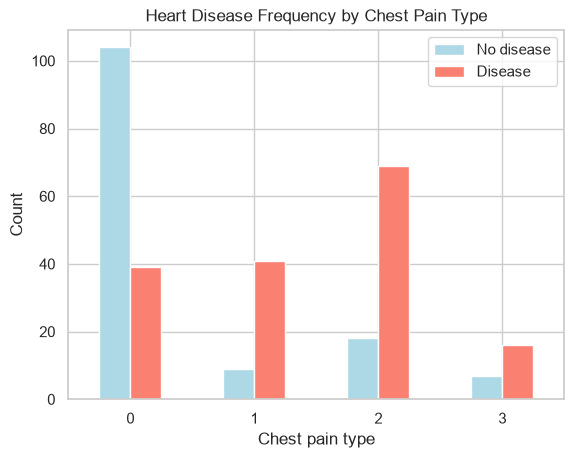

In [129]:
cp_target = pd.crosstab(df["cp"], df["target"])
display(cp_target)
cp_target.plot(kind="bar", color=["lightblue", "salmon"])
plt.title("Heart Disease Frequency by Chest Pain Type")
plt.xlabel("Chest pain type")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.legend(["No disease", "Disease"])
plt.show()


Chest-pain categories have different positive proportions. Their interpretation depends on the dataset dictionary and domain knowledge.


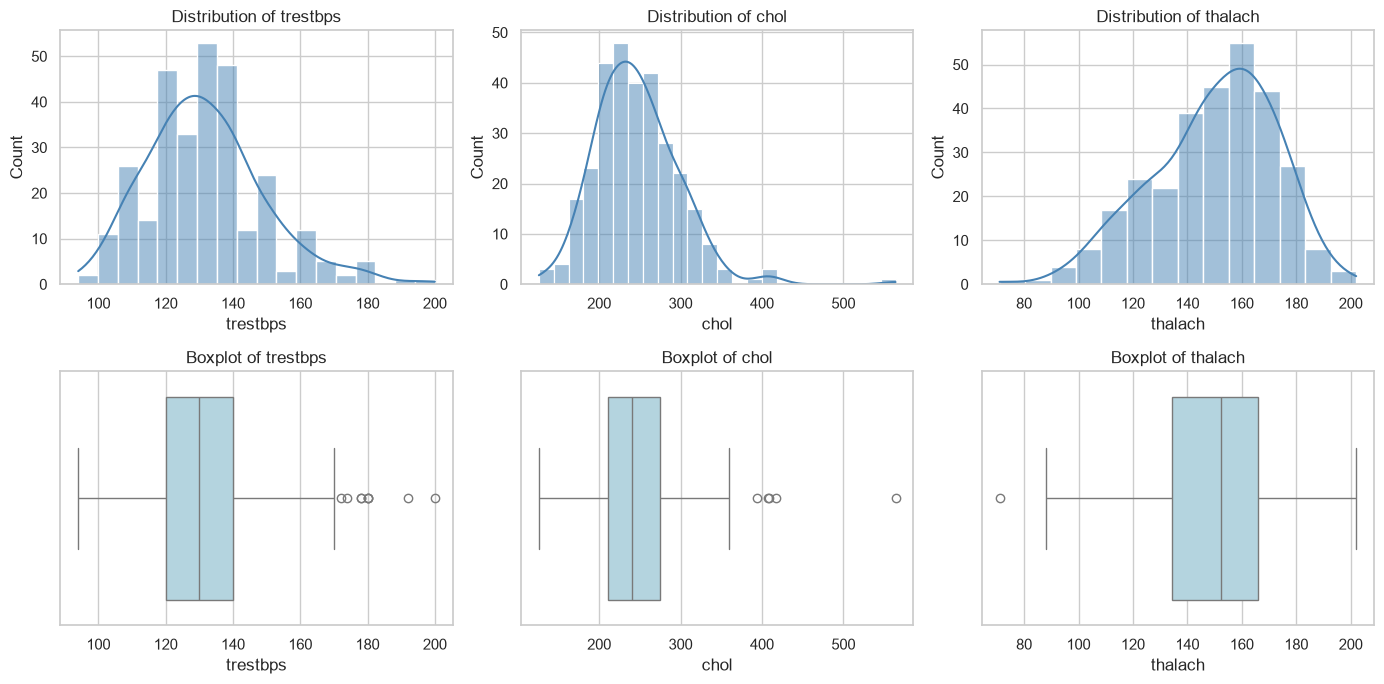

In [130]:
missing_columns = ["trestbps", "chol", "thalach"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for index, column in enumerate(missing_columns):
    sns.histplot(df[column], kde=True, ax=axes[0, index], color="steelblue")
    axes[0, index].set_title(f"Distribution of {column}")
    sns.boxplot(x=df[column], ax=axes[1, index], color="lightblue")
    axes[1, index].set_title(f"Boxplot of {column}")
plt.tight_layout()
plt.show()


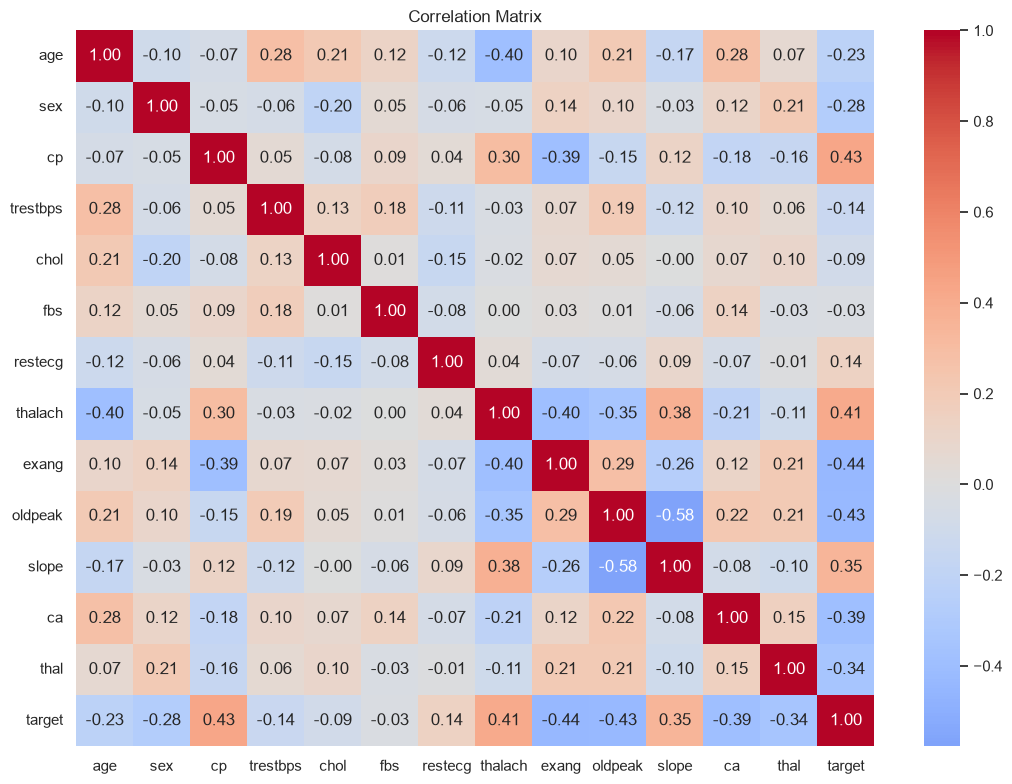

In [131]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


`cp`, `thalach`, `oldpeak`, `exang`, `ca`, and `thal` show notable linear associations with the target. Correlation is not feature importance and does not imply causation.


## 4. Train/test split

The test set is separated before preprocessing. Imputation, encoding and scaling stay inside pipelines to prevent leakage.


In [132]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
display(pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index(),
    "test": y_test.value_counts(normalize=True).sort_index(),
}))


Training shape: (242, 13)
Test shape: (61, 13)


,train,test
target,,
0,0.454545,0.459016
1,0.545455,0.540984


## 5. Preprocessing pipelines

- Mean imputation: `trestbps`, `thalach`
- Median imputation: `chol`
- Scaling: distance-based and linear models
- One-hot encoding: categorical medical codes


In [133]:
mean_columns = ["trestbps", "thalach"]
median_columns = ["chol"]
other_numeric_columns = ["age", "oldpeak", "ca"]
binary_columns = ["sex", "fbs", "exang"]
categorical_columns = ["cp", "restecg", "slope", "thal"]

scaled_preprocessor = ColumnTransformer([
    ("mean_scaled", Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", StandardScaler()),
    ]), mean_columns),
    ("median_scaled", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), median_columns),
    ("numeric_scaled", StandardScaler(), other_numeric_columns),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_columns),
    ("binary", "passthrough", binary_columns),
])

tree_preprocessor = ColumnTransformer([
    ("mean_imputer", SimpleImputer(strategy="mean"), mean_columns),
    ("median_imputer", SimpleImputer(strategy="median"), median_columns),
    ("numeric", "passthrough", other_numeric_columns),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_columns),
    ("binary", "passthrough", binary_columns),
])


## 6. Baseline comparison

All models use the same stratified folds. The dummy classifier defines the minimum baseline to beat.


In [134]:
models = {
    "Dummy Classifier": Pipeline([
        ("preprocessor", clone(tree_preprocessor)),
        ("classifier", DummyClassifier(strategy="most_frequent")),
    ]),
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(scaled_preprocessor)),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]),
    "K-Nearest Neighbors": Pipeline([
        ("preprocessor", clone(scaled_preprocessor)),
        ("classifier", KNeighborsClassifier()),
    ]),
    "Decision Tree": Pipeline([
        ("preprocessor", clone(tree_preprocessor)),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", clone(tree_preprocessor)),
        ("classifier", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy", "precision": "precision", "recall": "recall",
    "f1": "f1", "roc_auc": "roc_auc",
}


In [135]:
def compare_models(model_dictionary, cross_validator):
    rows = {}
    for name, model in model_dictionary.items():
        scores = cross_validate(
            model, X_train, y_train, cv=cross_validator,
            scoring=scoring, n_jobs=-1,
        )
        rows[name] = {
            f"{metric}_mean": scores[f"test_{metric}"].mean()
            for metric in scoring
        }
        rows[name].update({
            f"{metric}_std": scores[f"test_{metric}"].std()
            for metric in scoring
        })
    return (
        pd.DataFrame.from_dict(rows, orient="index")
        .rename_axis("Model")
        .sort_values("accuracy_mean", ascending=False)
    )

baseline_results_df = compare_models(models, cv)
baseline_results_df.round(3)


,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,accuracy_std,precision_std,recall_std,f1_std,roc_auc_std
Model,,,,,,,,,,
Logistic Regression,0.814,0.814,0.855,0.833,0.885,0.063,0.062,0.067,0.059,0.043
Random Forest,0.806,0.827,0.819,0.822,0.878,0.066,0.071,0.065,0.059,0.051
K-Nearest Neighbors,0.802,0.808,0.833,0.820,0.866,0.055,0.043,0.071,0.053,0.046
Decision Tree,0.736,0.784,0.728,0.752,0.737,0.080,0.102,0.064,0.069,0.084
Dummy Classifier,0.545,0.545,1.000,0.706,0.500,0.005,0.005,0.000,0.004,0.000


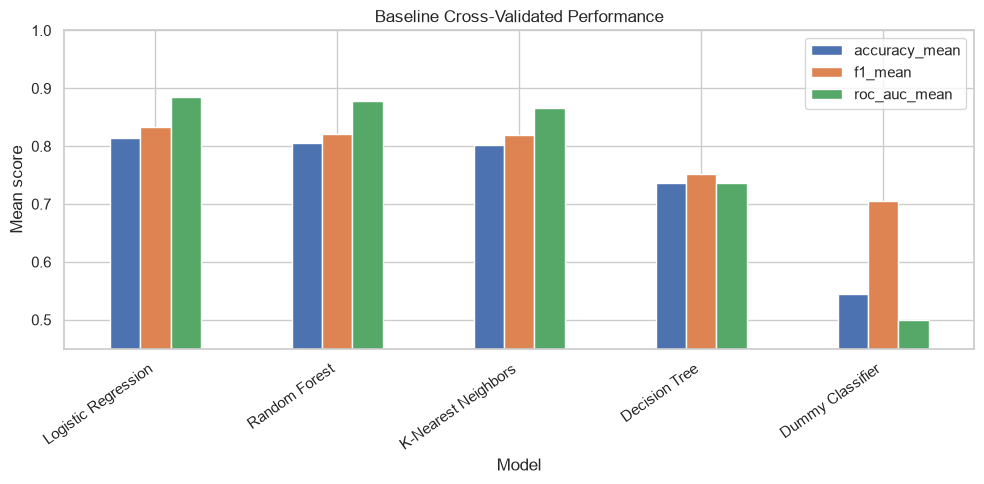

In [136]:
baseline_results_df[["accuracy_mean", "f1_mean", "roc_auc_mean"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0.45, 1.0)
)
plt.title("Baseline Cross-Validated Performance")
plt.ylabel("Mean score")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


Small differences between strong models may be sampling noise, especially with only 242 training observations.


## 7. Tune the core models

The searches use only the training set. They optimize **accuracy** because this section specifically investigates whether accuracy can be improved.


In [137]:
log_reg_grid = {
    "classifier__C": np.logspace(-4, 4, 30),
    "classifier__solver": ["liblinear"],
    "classifier__penalty": ["l1", "l2"],
    "classifier__class_weight": [None, "balanced"],
}
log_reg_search = GridSearchCV(
    models["Logistic Regression"], log_reg_grid, cv=cv,
    scoring="accuracy", n_jobs=-1, return_train_score=True,
)
log_reg_search.fit(X_train, y_train)
print("Best accuracy:", round(log_reg_search.best_score_, 3))
print("Best parameters:", log_reg_search.best_params_)


Best accuracy: 0.847
Best parameters: {'classifier__C': np.float64(0.20433597178569418), 'classifier__class_weight': None, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}


In [138]:
rf_grid = {
    "classifier__n_estimators": [200, 300, 500, 800, 1000],
    "classifier__max_depth": [None, 3, 5, 8, 12],
    "classifier__min_samples_split": [2, 5, 10, 15],
    "classifier__min_samples_leaf": [1, 2, 4, 8],
    "classifier__max_features": ["sqrt", "log2", None],
    "classifier__class_weight": [None, "balanced", "balanced_subsample"],
}
rf_search = RandomizedSearchCV(
    models["Random Forest"], rf_grid, n_iter=40, cv=cv,
    scoring="accuracy", n_jobs=-1, random_state=RANDOM_STATE,
    return_train_score=True,
)
rf_search.fit(X_train, y_train)
print("Best accuracy:", round(rf_search.best_score_, 3))
print("Best parameters:", rf_search.best_params_)


Best accuracy: 0.835
Best parameters: {'classifier__n_estimators': 500, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt', 'classifier__max_depth': None, 'classifier__class_weight': None}


In [139]:
knn_grid = {
    "classifier__n_neighbors": list(range(3, 41)),
    "classifier__weights": ["uniform", "distance"],
    "classifier__p": [1, 2],
}
knn_search = GridSearchCV(
    models["K-Nearest Neighbors"], knn_grid, cv=cv,
    scoring="accuracy", n_jobs=-1, return_train_score=True,
)
knn_search.fit(X_train, y_train)
print("Best accuracy:", round(knn_search.best_score_, 3))
print("Best parameters:", knn_search.best_params_)


Best accuracy: 0.847
Best parameters: {'classifier__n_neighbors': 7, 'classifier__p': 1, 'classifier__weights': 'uniform'}


## 8. Advanced ensemble models

- **AdaBoost:** sequentially corrects previous errors
- **CatBoost:** gradient boosting with native categorical-feature support

Complex models are retained only when validation improves consistently.


In [141]:
ada_pipeline = Pipeline([
    ("preprocessor", clone(tree_preprocessor)),
    ("classifier", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        random_state=RANDOM_STATE,
    )),
])
ada_grid = {
    "classifier__n_estimators": [25, 50, 75, 100, 150, 200, 300, 500],
    "classifier__learning_rate": [0.005, 0.01, 0.02, 0.03, 0.05, 0.1, 0.2, 0.5, 1.0],
    "classifier__estimator__max_depth": [1, 2, 3],
    "classifier__estimator__min_samples_leaf": [1, 2, 4, 6, 10, 15],
    "classifier__estimator__class_weight": [None, "balanced"],
}
ada_search = RandomizedSearchCV(
    ada_pipeline, ada_grid, n_iter=35, cv=cv,
    scoring="accuracy", n_jobs=-1, random_state=RANDOM_STATE,
    return_train_score=True,
)
ada_search.fit(X_train, y_train)
print("Best accuracy:", round(ada_search.best_score_, 3))
print("Best parameters:", ada_search.best_params_)


Best accuracy: 0.835
Best parameters: {'classifier__n_estimators': 200, 'classifier__learning_rate': 0.03, 'classifier__estimator__min_samples_leaf': 4, 'classifier__estimator__max_depth': 1, 'classifier__estimator__class_weight': None}


In [142]:
catboost_categorical_columns = (
    "sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"
)
catboost_model = CatBoostClassifier(
    cat_features=catboost_categorical_columns,
    verbose=False,
    random_seed=RANDOM_STATE,
    allow_writing_files=False,
    thread_count=1,
)
catboost_grid = {
    "iterations": [100, 150, 200, 300, 500, 700],
    "depth": [2, 3, 4, 5, 6],
    "learning_rate": [0.01, 0.02, 0.03, 0.05, 0.08, 0.1],
    "l2_leaf_reg": [1, 3, 5, 7, 10, 15, 20],
    "random_strength": [0, 0.25, 0.5, 1, 2],
    "bagging_temperature": [0, 0.5, 1, 2, 5],
}
catboost_search = RandomizedSearchCV(
    catboost_model, catboost_grid, n_iter=35, cv=cv,
    scoring="accuracy", n_jobs=-1, random_state=RANDOM_STATE,
    return_train_score=True,
)
catboost_search.fit(X_train, y_train)
print("Best accuracy:", round(catboost_search.best_score_, 3))
print("Best parameters:", catboost_search.best_params_)


Best accuracy: 0.843
Best parameters: {'random_strength': 1, 'learning_rate': 0.01, 'l2_leaf_reg': 5, 'iterations': 500, 'depth': 4, 'bagging_temperature': 1}


## 9. Stable comparison of tuned models

Candidates are compared with repeated stratified cross-validation. The mean score matters more than the best fold.


In [143]:
tuned_models = {
    "Logistic Regression": log_reg_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_,
    "K-Nearest Neighbors": knn_search.best_estimator_,
    "AdaBoost": ada_search.best_estimator_,
    "CatBoost": catboost_search.best_estimator_,
}
repeated_cv = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=3, random_state=RANDOM_STATE
)
tuned_results_df = compare_models(tuned_models, repeated_cv)
tuned_results_df.round(3)


,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,accuracy_std,precision_std,recall_std,f1_std,roc_auc_std
Model,,,,,,,,,,
CatBoost,0.848,0.852,0.876,0.862,0.904,0.057,0.054,0.076,0.054,0.037
Logistic Regression,0.844,0.845,0.876,0.859,0.895,0.050,0.045,0.071,0.049,0.039
Random Forest,0.836,0.839,0.866,0.851,0.906,0.056,0.046,0.084,0.056,0.037
K-Nearest Neighbors,0.832,0.835,0.863,0.848,0.891,0.057,0.051,0.075,0.055,0.036
AdaBoost,0.829,0.817,0.886,0.849,0.885,0.061,0.056,0.065,0.055,0.048


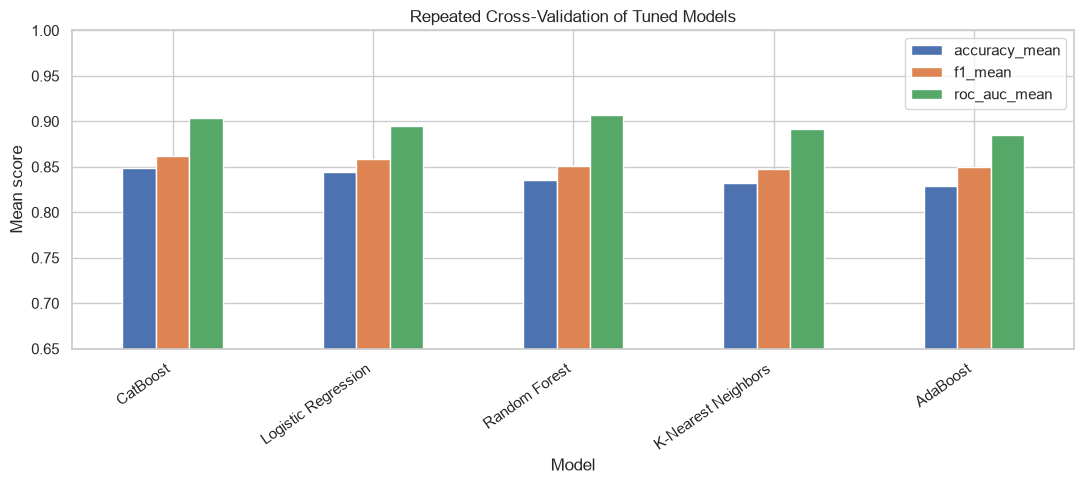

In [144]:
tuned_results_df[["accuracy_mean", "f1_mean", "roc_auc_mean"]].plot(
    kind="bar", figsize=(11, 5), ylim=(0.65, 1.0)
)
plt.title("Repeated Cross-Validation of Tuned Models")
plt.ylabel("Mean score")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


A difference of one or two percentage points may not be meaningful when standard deviations overlap.


## 10. Out-of-fold error analysis

Out-of-fold predictions estimate errors on observations excluded from the corresponding fitted fold.


In [145]:
finalist_names = tuned_results_df.head(3).index.tolist()
finalist_models = {name: tuned_models[name] for name in finalist_names}
oof_predictions = {}
oof_probabilities = {}

for name, model in finalist_models.items():
    oof_predictions[name] = cross_val_predict(
        model, X_train, y_train, cv=cv, method="predict", n_jobs=-1
    )
    oof_probabilities[name] = cross_val_predict(
        model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
    )[:, 1]

error_rows = {}
for name, predictions in oof_predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_train, predictions).ravel()
    error_rows[name] = {"TN": tn, "FP": fp, "FN": fn, "TP": tp}

error_analysis_df = pd.DataFrame.from_dict(error_rows, orient="index")
error_analysis_df.index.name = "Model"
error_analysis_df


,TN,FP,FN,TP
Model,,,,
CatBoost,88,22,16,116
Logistic Regression,89,21,16,116
Random Forest,88,22,18,114


False negatives are positive cases missed by the model. False positives are negative cases flagged as positive.


## 11. Probability calibration

Lower Brier score and log loss indicate better probability estimates. Calibration does not measure accuracy directly.


,brier_score,log_loss
CatBoost,0.123,0.396
Random Forest,0.129,0.407
Logistic Regression,0.130,0.414


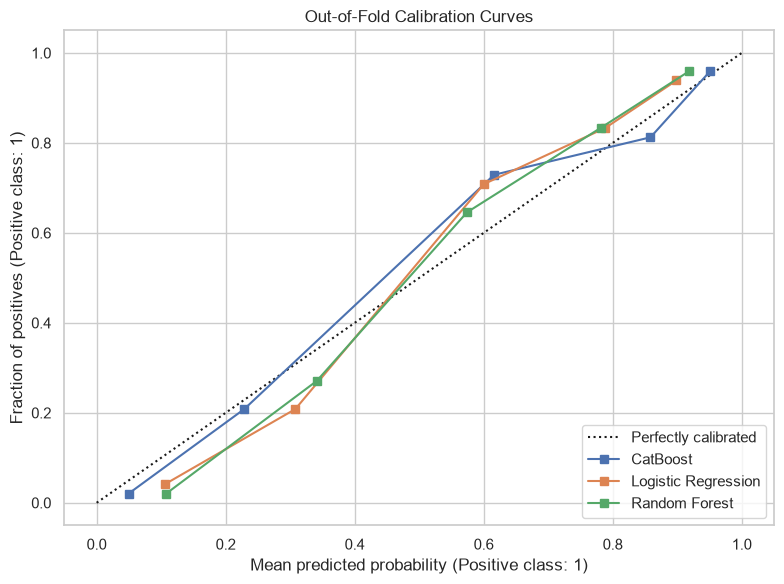

In [146]:
calibration_results = {
    name: {
        "brier_score": brier_score_loss(y_train, probabilities),
        "log_loss": log_loss(y_train, probabilities),
    }
    for name, probabilities in oof_probabilities.items()
}
calibration_results_df = pd.DataFrame.from_dict(
    calibration_results, orient="index"
).sort_values("brier_score")
display(calibration_results_df.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
for name, probabilities in oof_probabilities.items():
    CalibrationDisplay.from_predictions(
        y_train, probabilities, n_bins=5, strategy="quantile", name=name, ax=ax
    )
ax.set_title("Out-of-Fold Calibration Curves")
plt.tight_layout()
plt.show()


## 12. Threshold sensitivity

The default threshold of 0.50 is retained for accuracy. Lower thresholds increase recall but generally reduce precision and accuracy.


In [147]:
threshold_rows = []
for name, probabilities in oof_probabilities.items():
    for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
        predictions = (probabilities >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_train, predictions).ravel()
        threshold_rows.append({
            "Model": name, "Threshold": threshold,
            "Accuracy": accuracy_score(y_train, predictions),
            "Precision": precision_score(y_train, predictions),
            "Recall": recall_score(y_train, predictions),
            "F1": f1_score(y_train, predictions), "FP": fp, "FN": fn,
        })
threshold_results_df = pd.DataFrame(threshold_rows)
threshold_results_df.round(3)


,Model,Threshold,Accuracy,Precision,Recall,F1,FP,FN
0,CatBoost,0.3,0.835,0.799,0.932,0.860,31,9
1,CatBoost,0.4,0.851,0.833,0.909,0.870,24,12
2,CatBoost,0.5,0.843,0.841,0.879,0.859,22,16
3,CatBoost,0.6,0.814,0.854,0.795,0.824,18,27
4,CatBoost,0.7,0.785,0.857,0.727,0.787,16,36
5,Logistic Regression,0.3,0.777,0.729,0.939,0.821,46,8
6,Logistic Regression,0.4,0.831,0.794,0.932,0.857,32,9
7,Logistic Regression,0.5,0.847,0.847,0.879,0.862,21,16
8,Logistic Regression,0.6,0.798,0.843,0.773,0.806,19,30
9,Logistic Regression,0.7,0.769,0.865,0.682,0.763,14,42


Do not choose a threshold because it improves the test score. It must be fixed from training predictions and linked to a clear objective.


## 13. Final model and holdout evaluation

CatBoost is selected from repeated cross-validation because it provides the best overall combination of accuracy, F1-score and probability calibration.

The holdout contains only 61 observations, so repeated cross-validation remains the main performance estimate.


In [148]:
FINAL_MODEL_NAME = "CatBoost"
FINAL_THRESHOLD = 0.50
final_model = clone(tuned_models[FINAL_MODEL_NAME])
final_model.fit(X_train, y_train)

test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= FINAL_THRESHOLD).astype(int)
final_test_results = pd.Series({
    "accuracy": accuracy_score(y_test, test_predictions),
    "precision": precision_score(y_test, test_predictions),
    "recall": recall_score(y_test, test_predictions),
    "f1": f1_score(y_test, test_predictions),
    "roc_auc": roc_auc_score(y_test, test_probabilities),
})
print("Selected model:", FINAL_MODEL_NAME)
print("Threshold:", FINAL_THRESHOLD)
display(final_test_results.round(3))


Selected model: CatBoost
Threshold: 0.5


accuracy     0.836
precision    0.795
recall       0.939
f1           0.861
roc_auc      0.899
dtype: float64

              precision    recall  f1-score   support

  No disease       0.91      0.71      0.80        28
     Disease       0.79      0.94      0.86        33

    accuracy                           0.84        61
   macro avg       0.85      0.83      0.83        61
weighted avg       0.85      0.84      0.83        61



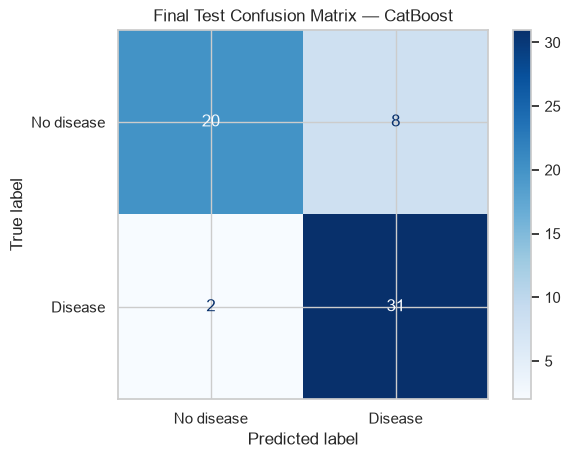

In [149]:
print(classification_report(
    y_test, test_predictions, target_names=["No disease", "Disease"]
))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions,
    display_labels=["No disease", "Disease"], cmap="Blues"
)
plt.title(f"Final Test Confusion Matrix — {FINAL_MODEL_NAME}")
plt.show()


### Final test result

CatBoost correctly classifies 51 of 61 holdout observations.

- Accuracy: **0.836**
- Precision: **0.795**
- Recall: **0.939**
- F1-score: **0.861**
- False positives: **8**
- False negatives: **2**

The high recall is encouraging for this experiment, but the small sample prevents clinical conclusions.


The holdout contains only 61 observations. A few predictions can move accuracy by several percentage points, so report it with repeated-CV scores.


## 14. Model interpretation

Permutation importance measures how much ROC-AUC decreases when one feature is shuffled. It does not show causality.


,feature,importance_mean,importance_std
4,chol,-0.014,0.010
6,restecg,-0.002,0.006
3,trestbps,-0.001,0.002
5,fbs,-0.000,0.000
0,age,0.002,0.004
8,exang,0.004,0.008
7,thalach,0.005,0.005
9,oldpeak,0.013,0.010
1,sex,0.014,0.006
10,slope,0.016,0.012


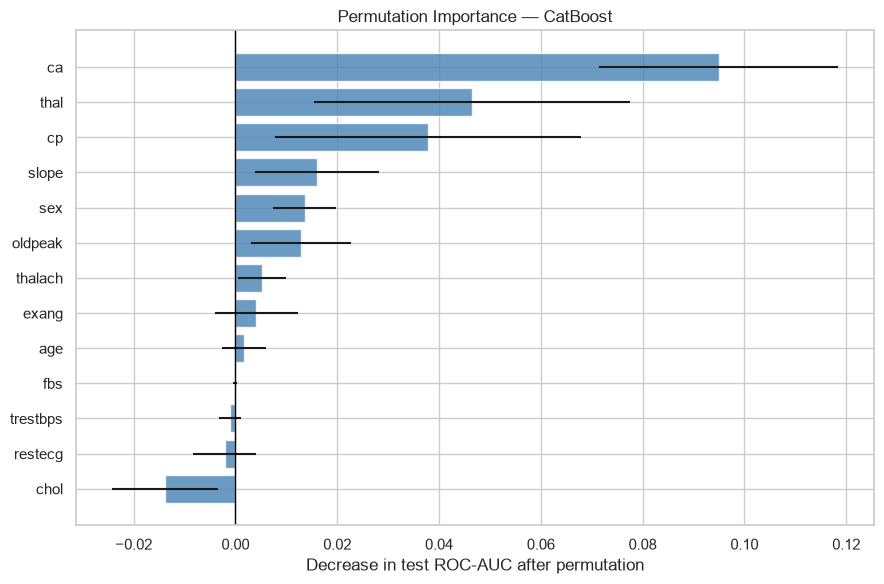

In [150]:
permutation_results = permutation_importance(
    final_model, X_test, y_test, scoring="roc_auc",
    n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1,
)
importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": permutation_results.importances_mean,
    "importance_std": permutation_results.importances_std,
}).sort_values("importance_mean")
display(importance_df.round(3))

plt.figure(figsize=(9, 6))
plt.barh(
    importance_df["feature"], importance_df["importance_mean"],
    xerr=importance_df["importance_std"], color="steelblue", alpha=0.8,
)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Decrease in test ROC-AUC after permutation")
plt.title(f"Permutation Importance — {FINAL_MODEL_NAME}")
plt.tight_layout()
plt.show()


## 15. Limitations

- Only 303 observations are available.
- The holdout contains only 61 observations.
- Category definitions require domain verification.
- Hyperparameter search can overfit cross-validation.
- There is no external clinical validation.
- Predictions must not guide medical decisions.


## 16. Save the deployment model

The selected CatBoost configuration is refitted on all 303 observations before export. The native model file and JSON metadata will be loaded by the future Streamlit application.


In [ ]:
import json

deployment_model = CatBoostClassifier(
    random_strength=1,
    learning_rate=0.01,
    l2_leaf_reg=5,
    iterations=500,
    depth=4,
    bagging_temperature=1,
    cat_features=catboost_categorical_columns,
    verbose=False,
    random_seed=RANDOM_STATE,
    allow_writing_files=False,
)
deployment_model.fit(X, y)

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

deployment_model.save_model(MODEL_DIR / "heart_disease_catboost.cbm")

model_metadata = {
    "model_name": "CatBoostClassifier",
    "threshold": 0.50,
    "feature_order": X.columns.tolist(),
    "categorical_features": list(catboost_categorical_columns),
    "target_mapping": {"no": 0, "yes": 1},
    "sex_mapping": {"female": 0, "male": 1},
    "cv_accuracy_mean": 0.848,
    "cv_accuracy_std": 0.057,
    "holdout_accuracy": 0.836,
    "disclaimer": "Educational demonstration only; not a medical diagnostic tool.",
}

with open(MODEL_DIR / "model_metadata.json", "w", encoding="utf-8") as file:
    json.dump(model_metadata, file, indent=2)

print("Saved:", MODEL_DIR / "heart_disease_catboost.cbm")
print("Saved:", MODEL_DIR / "model_metadata.json")


## 17. Final conclusion

CatBoost is retained as the final model.

- Repeated-CV accuracy: **0.848 ± 0.057**
- Repeated-CV F1-score: **0.862 ± 0.054**
- Repeated-CV ROC-AUC: **0.904 ± 0.037**
- Holdout accuracy: **0.836**
- Holdout recall: **0.939**
- Holdout confusion matrix: **20 TN, 8 FP, 2 FN, 31 TP**

CatBoost slightly outperforms Logistic Regression on average and produces the best calibrated probabilities. However, their uncertainty intervals overlap, so the improvement should be described as modest rather than definitive.

The final system is an educational demonstration, not a clinical diagnostic tool.
